# SMARTS exercises

You already know SMILES and how to use them in RDKit. **SMARTS** uses the same ideas, but every atom and bond is a *query* instead of a fixed structure.

How it works: write a SMARTS string for each exercise, run the check cell, and read the feedback. Solutions are at the end, so try first.

Quick reminders:

| Pattern | Meaning |
|---|---|
| `C` / `c` | aliphatic / aromatic carbon |
| `[#6]` | any carbon |
| `[C,N]` | C **or** N |
| `[C;R]` | C **and** in a ring (`;` = AND) |
| `!R` | **not** in a ring |
| `X3`, `H1` | 3 total connections, 1 hydrogen |
| `*`, `~`, `@` | any atom, any bond, ring bond |

In [1]:
from rdkit import Chem
from rdkit.Chem import Draw

Quick demo:

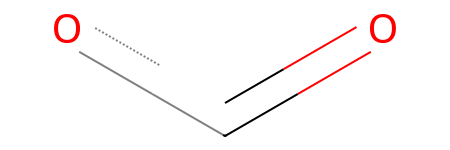

In [3]:
query_mol = Chem.MolFromSmarts("[CX3](=O)[OX2H1]")
query_mol

# Remember, C in SMARTS is not a carbon, just C
# CX3 Carbon with three bonds

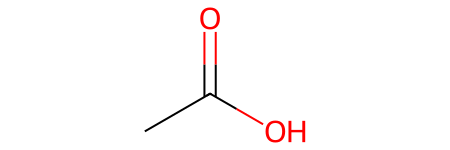

In [ ]:
mol = Chem.MolFromSmiles("CC(=O)O") # Acetic acid
mol

# In SMILES, all unoccupied will automatically get a hydrogen; goes through standard valence model(just O as SMILES is water)
# Salts and metal complexes can cause problems  

In [6]:
mol.HasSubstructMatch(query_mol)

True

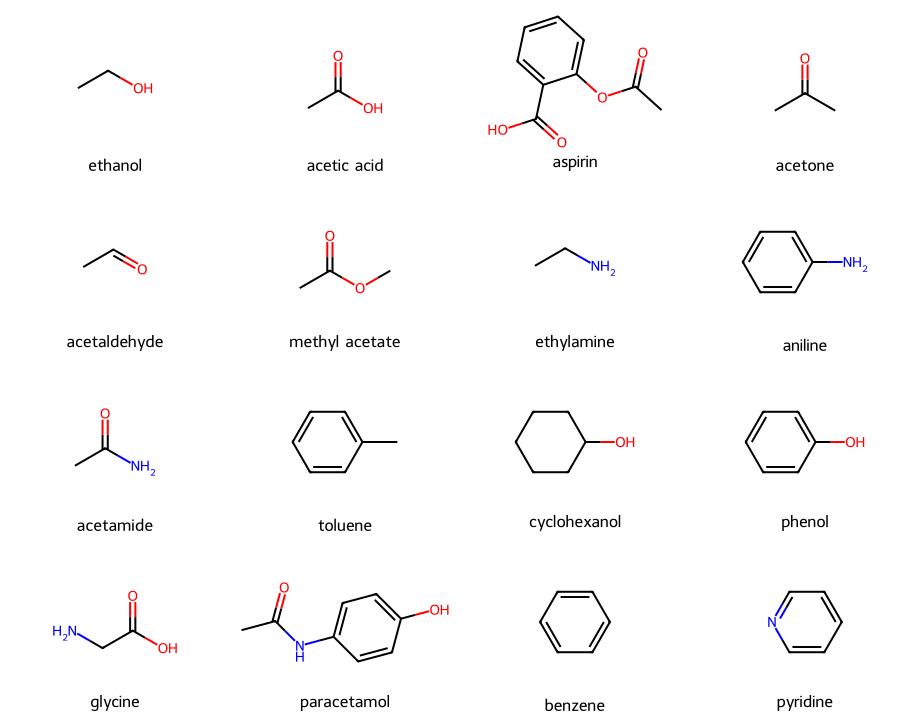

In [5]:
smiles = {
    "ethanol":       "CCO",
    "acetic acid":   "CC(=O)O",
    "aspirin":       "CC(=O)Oc1ccccc1C(=O)O",
    "acetone":       "CC(=O)C",
    "acetaldehyde":  "CC=O",
    "methyl acetate":"CC(=O)OC",
    "ethylamine":    "CCN",
    "aniline":       "Nc1ccccc1",
    "acetamide":     "CC(=O)N",
    "toluene":       "Cc1ccccc1",
    "cyclohexanol":  "OC1CCCCC1",
    "phenol":        "Oc1ccccc1",
    "glycine":       "NCC(=O)O",
    "paracetamol":   "CC(=O)Nc1ccc(O)cc1",
    "benzene":       "c1ccccc1",
    "pyridine":      "c1ccncc1",
}
mols = {name: Chem.MolFromSmiles(smi) for name, smi in smiles.items()}

Draw.MolsToGridImage(list(mols.values()), legends=list(mols.keys()),
                     molsPerRow=4, subImgSize=(230, 180))

In [ ]:
# Helper functions: just run this cell.
EXPECTED = {
    "ex1": {"acetic acid", "aspirin", "glycine"},
    "ex2": {"aspirin", "aniline", "toluene", "phenol", "paracetamol", "benzene", "pyridine"},
    "ex3": {"ethanol", "cyclohexanol"},
    "ex4": {"acetone"},
    "ex5": {"acetaldehyde"},
    "ex6": {"ethylamine", "glycine"},
    "ex7": {"aspirin", "aniline", "phenol", "paracetamol"},
    "ex8": {"aspirin", "methyl acetate"},
    "ex9": {"acetamide", "paracetamol"},
    "ex10": {"phenol", "paracetamol"},
}

def matching(smarts):
    patt = Chem.MolFromSmarts(smarts)
    if patt is None:
        return None, set()
    return patt, {n for n, m in mols.items() if m.HasSubstructMatch(patt)}

def check(ex, smarts):
    patt, hits = matching(smarts)
    if patt is None:
        print("Not a valid SMARTS string. Check brackets and spelling.")
        return
    expected = EXPECTED[ex]
    if hits == expected:
        print("Correct!", sorted(hits))
    else:
        missing, extra = expected - hits, hits - expected
        print("Not quite.")
        if missing: print("  Should match, but doesn't:", sorted(missing))
        if extra:   print("  Matches, but shouldn't:   ", sorted(extra))

def show(smarts):
    # draws every matching molecule with the matched atoms highlighted
    patt, hits = matching(smarts)
    if patt is None or not hits:
        print("No matches to draw.")
        return None
    names = [n for n in mols if n in hits]
    ms = [mols[n] for n in names]
    hl = [sorted({a for t in m.GetSubstructMatches(patt) for a in t}) for m in ms]
    return Draw.MolsToGridImage(ms, legends=names, highlightAtomLists=hl,
                                molsPerRow=4, subImgSize=(230, 180))

## Part 0: Predict, then run

For each line, decide whether the result is `True` or `False` **before** running the cell.

In [ ]:
tests = [
    ("Oc1ccccc1", "CO"),      # phenol,   pattern: C-O
    ("Oc1ccccc1", "cO"),      # phenol,   pattern: aromatic c-O
    ("Oc1ccccc1", "[#6]O"),   # phenol,   pattern: any carbon-O
    ("c1ccncc1",  "N"),       # pyridine, pattern: aliphatic N
    ("c1ccncc1",  "[#7]"),    # pyridine, pattern: any nitrogen
    ("CCO",       "[OH]"),    # ethanol,  pattern: O with one H
]
for smi, sma in tests:
    result = Chem.MolFromSmiles(smi).HasSubstructMatch(Chem.MolFromSmarts(sma))
    print(f"{smi:12s} {sma:8s} {result}")

## Part 1: Worked example

Carboxylic acids: a carbon with 3 connections, double-bonded to O, and bonded to an OH.

In [ ]:
smarts = "[CX3](=O)[OX2H1]"
check("ex1", smarts)
show(smarts)

## Part 2: Atoms

**Exercise 2.** Write a SMARTS that matches any **aromatic carbon**.

In [ ]:
smarts = ""   # TODO
check("ex2", smarts)

**Exercise 3.** Write a SMARTS for an **alcohol OH on an sp3 carbon** (so phenols and acids must *not* match).

Hint: `X4` = four total connections (a saturated carbon).

In [ ]:
smarts = ""   # TODO
check("ex3", smarts)

## Part 3: Carbonyl compounds

**Exercise 4.** Write a SMARTS for a **ketone**: a carbonyl carbon bonded to two carbons.

Hint: use `[#6]` for the neighbours. Acids, esters and amides must not match.

In [ ]:
smarts = ""   # TODO
check("ex4", smarts)

**Exercise 5.** Write a SMARTS for an **aldehyde**: a carbonyl carbon with exactly one hydrogen.

Hint: `H1` counts hydrogens on the atom.

In [ ]:
smarts = ""   # TODO
check("ex5", smarts)

## Part 4: Logic (`,` `;` `!`)

**Exercise 6.** Write a SMARTS for a **primary aliphatic amine**: an N with 2 H attached to an sp3 carbon.

Aniline and acetamide must not match.

In [ ]:
smarts = ""   # TODO
check("ex6", smarts)

**Exercise 7.** Write a SMARTS for an **aromatic carbon bonded to N or O** (use the comma for OR).

Look at pyridine in your result: does it match? Why or why not?

In [ ]:
smarts = ""   # TODO
check("ex7", smarts)

## Part 5: Combining ideas

**Exercise 8.** Write a SMARTS for an **ester**: `C(=O)` bonded to an O which is bonded to another carbon.

The O of an acid (O-H) must not match.

In [ ]:
smarts = ""   # TODO
check("ex8", smarts)

**Exercise 9.** Write a SMARTS for an **amide**: carbonyl carbon bonded to a nitrogen.

In [ ]:
smarts = ""   # TODO
check("ex9", smarts)

**Exercise 10 (challenge).** Write a SMARTS for a **phenol OH**: a hydroxyl on an aromatic carbon.

In [ ]:
smarts = ""   # TODO
check("ex10", smarts)

## Part 6: Counting atoms and rings

**Exercise 11.** How many atoms of aspirin are **not in a ring**?

Write a SMARTS for a single atom that is not in a ring, then count matches with `GetSubstructMatches`. Compare with a count by hand from the drawing.

In [ ]:
smarts = ""   # TODO
patt = Chem.MolFromSmarts(smarts)
matches = mols["aspirin"].GetSubstructMatches(patt)
print(len(matches), "atoms not in a ring")

**Exercise 12 (free play).** Pick any molecule from the list or add your own SMILES, write a SMARTS for a feature you find interesting, and use `show(smarts)` to highlight it.

In [ ]:
smarts = ""   # TODO
show(smarts)

---
## Solutions

*Try everything first.* Several answers are possible; yours is correct if `check` says so.

**Part 0:** `False`, `True`, `True`, `False`, `True`, `True`. In SMARTS, `C` is aliphatic only and `N` is aliphatic only, so the aromatic `c` and `n` need `c`/`n` or the any-element form `[#6]`/`[#7]`.

| Exercise | Solution |
|---|---|
| 2 | `c` |
| 3 | `[CX4][OX2H]` |
| 4 | `[#6][CX3](=O)[#6]` |
| 5 | `[CX3H1](=O)[#6]` |
| 6 | `[NX3;H2][CX4]` |
| 7 | `c[N,O]` (pyridine fails: its N is aromatic `n`, so `[N,O]` does not match it) |
| 8 | `[CX3](=O)[OX2][#6]` |
| 9 | `[CX3](=O)[NX3]` |
| 10 | `c[OX2H]` |
| 11 | `[!R]` (7 atoms) |